# Notebook 09 — Explainability, Quantitatively Validated

**Project:** A Multi-Modal Deep Learning Approach for Eggshell Micro-Crack Morphology Analysis and Root-Cause Diagnosis in Poultry Breeder Farms
**Author:** M.P.N. Sharindi (Coventry Index 16110429)
**Stage:** 09 of 12 — answers RQ4 and completes Objective 3

---

### Why this notebook is not decoration

Most applied papers show three pretty heatmaps and assert that the model "focuses on the defect".
That is not evidence. This notebook measures whether the explanation lands on the crack, against
the 335 annotation polygons, with three metrics per egg and a classical reference point.

There is also a comparison most work cannot make. The selected model is `multitask_seg`, so it has
**two** sources of localisation:

* **Grad-CAM and Grad-CAM++** — post-hoc, derived from gradients, available for any model
* **the segmentation head** — trained directly on the polygons, available only because formulation
  (d) was chosen

Whether the supervised head beats the post-hoc explanation is a real question with a real answer,
and it is the empirical justification for having chosen formulation (d) in notebook 07.

### Metrics

| metric | meaning | 
|---|---|
| **pointing game** | does the single highest-activation pixel fall inside the annotated polygon? Binary per egg |
| **energy inside** | what fraction of total activation mass falls inside the polygon? |
| **IoU @ top-k** | overlap between the top-activation region and the polygon, thresholded at the polygon's own area |

### Reference points

A random heatmap scores, on average, the polygon's area fraction — a few per cent. The classical
ridge detector from notebook 04 recovered a **median 2.8 %** of annotated crack area. Those are the
bars to clear, and they are plotted alongside every result so a reader can see what the numbers
mean.

### Scope

Run on the **test set only**, using the models notebook 07 trained. No training happens here and
nothing is tuned.

---
## 0. Setup

In [ ]:
import os
os.environ["EGG_ARTEFACT_ROOT"] = r"E:\Degree\Final Research\Egg_Crack_Dataset\Eggshell-Diagnostic-Research\Artefact"

SELECTED = {"backbone": "efficientnet_b0", "formulation": "multitask_seg", "age_mode": "none"}
SEED_FOR_CAM = 42          # one seed; the ensemble has no single gradient path
CACHE_VARIANT = "neutral_fill"; CACHE_SIDE = 448; TRAIN_SIDE = 384
RANDOM_SEED = 42
N_GALLERY = 9

In [2]:
import sys, json, warnings
from pathlib import Path
from datetime import datetime
_here = Path.cwd()
_src = next((p / "src" for p in [_here, *_here.parents] if (p / "src" / "common").is_dir()), None)
if _src is None:
    raise RuntimeError("Run from Artefact/notebooks/ or set EGG_ARTEFACT_ROOT.")
sys.path.insert(0, str(_src))

import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
import torch, torch.nn.functional as F
from scipy import stats

from common import project_config as CFG
from common.data import EggDataset, build_crack_masks
from common.augmentation import standardise
from common.models import build_model

warnings.filterwarnings("ignore")
rng = np.random.default_rng(RANDOM_SEED)
STAGE = "09_explainability"
OUT = CFG.results_dir(STAGE); FIG_DIR, TAB_DIR = OUT / "figures", OUT / "tables"
PROC = CFG.DATA_DIR / "processed"
MODELS = CFG.MODELS_DIR / "final"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

splits = pd.read_csv(PROC / "splits.csv")
splits["label4"] = pd.Categorical(splits["label4"], categories=CFG.LABEL4, ordered=True)
cache = np.load(PROC / f"cache_{CACHE_VARIANT}_{CACHE_SIDE}.npy", mmap_mode="r")
MASKS = build_crack_masks(splits["crack_region"].tolist(), TRAIN_SIDE)

TEST = splits.index[splits["split"].eq("test")].to_numpy()
TEST_CRACKED = np.array([r for r in TEST if MASKS[r].sum() > 0])
print(f"test {len(TEST)} eggs, {len(TEST_CRACKED)} with an annotation polygon")
print("polygon area as % of frame:",
      round(float(np.mean([MASKS[r].mean() for r in TEST_CRACKED]) * 100), 2))

ckpt = MODELS / f"final_{SELECTED['backbone']}_{SELECTED['formulation']}_seed{SEED_FOR_CAM}.pt"
assert ckpt.exists(), f"missing {ckpt}; run notebook 07 first"
sd = torch.load(ckpt, map_location="cpu", weights_only=False)
model = build_model(SELECTED["backbone"], SELECTED["formulation"], 4, pretrained=False,
                    age_mode=SELECTED["age_mode"], img_size=TRAIN_SIDE)
model.load_state_dict(sd["state_dict"]); model.to(device).eval()
print(f"loaded {ckpt.name}")
S = {"stage": STAGE, "generated_at": datetime.now().isoformat(timespec="seconds"),
     "model": SELECTED, "n_test_cracked": int(len(TEST_CRACKED)),
     "mean_polygon_area_pct": round(float(np.mean([MASKS[r].mean() for r in TEST_CRACKED]) * 100), 3)}

test 98 eggs, 51 with an annotation polygon
polygon area as % of frame: 5.18
loaded final_efficientnet_b0_multitask_seg_seed42.pt


---
## 1. Grad-CAM, Grad-CAM++ and the segmentation head

Implemented directly rather than through a third-party package, so the gradient path is explicit
and the composed four-class score is handled correctly. The selected model has separate detection
and pattern heads, so the quantity differentiated is the log-probability of the composed four-class
prediction, not a raw logit from one head.

In [3]:
def prep(row):
    im = np.asarray(cache[row])
    if im.shape[0] != TRAIN_SIDE:
        im = cv2.resize(im, (TRAIN_SIDE, TRAIN_SIDE), interpolation=cv2.INTER_AREA)
    x = standardise(im).transpose(2, 0, 1)[None]
    return im, torch.tensor(x, dtype=torch.float32, device=device)

def forward_parts(x):
    """Replicates EggModel.forward but keeps the last feature map for gradients."""
    feats = model.backbone(x)
    A = feats[-1]; A.retain_grad()
    pooled = F.adaptive_avg_pool2d(A, 1).flatten(1)
    pooled = model.drop(pooled)
    det = model.head_det(pooled); pat = model.head_pat(pooled)
    pd_ = torch.softmax(det, 1); pp = torch.softmax(pat, 1)
    p4 = torch.cat([pd_[:, :1], pd_[:, 1:2] * pp], dim=1)   # Intact, Hairline, Star, Network
    seg = model.seg_head(feats)
    return A, p4, seg

def _norm(m):
    m = np.maximum(m, 0)
    return m / (m.max() + 1e-9)

def cams_for(row):
    """Return Grad-CAM, Grad-CAM++ and the segmentation map, all at TRAIN_SIDE, plus the prediction."""
    _, x = prep(row)
    model.zero_grad(set_to_none=True)
    A, p4, seg = forward_parts(x)
    cls = int(p4.argmax(1).item())
    score = torch.log(p4[0, cls] + 1e-9)
    score.backward(retain_graph=True)
    G = A.grad[0].detach()                     # (C, h, w)
    Ad = A[0].detach()

    w_cam = G.mean(dim=(1, 2))
    cam = torch.relu((w_cam[:, None, None] * Ad).sum(0)).cpu().numpy()

    # Grad-CAM++ weights
    g2, g3 = G ** 2, G ** 3
    denom = 2 * g2 + (Ad * g3).sum(dim=(1, 2), keepdim=True)
    alpha = g2 / torch.where(denom != 0, denom, torch.ones_like(denom))
    w_pp = (alpha * torch.relu(G)).sum(dim=(1, 2))
    campp = torch.relu((w_pp[:, None, None] * Ad).sum(0)).cpu().numpy()

    segmap = torch.sigmoid(seg)[0, 0].detach().cpu().numpy()
    up = lambda m: cv2.resize(_norm(m), (TRAIN_SIDE, TRAIN_SIDE), interpolation=cv2.INTER_LINEAR)
    return {"gradcam": up(cam), "gradcampp": up(campp), "segmentation": up(segmap)}, cls

def localisation_metrics(heat, mask):
    """Pointing game, energy inside the polygon, and IoU at the polygon's own area."""
    m = mask.astype(bool)
    if m.sum() < 10:
        return None
    peak = np.unravel_index(int(np.argmax(heat)), heat.shape)
    pointing = bool(m[peak])
    total = heat.sum()
    energy = float(heat[m].sum() / total) if total > 0 else 0.0
    k = int(m.sum())
    thr = np.partition(heat.ravel(), -k)[-k]      # top-k pixels, k = polygon area
    top = heat >= thr
    iou = float((top & m).sum() / max((top | m).sum(), 1))
    return {"pointing": pointing, "energy_inside": energy, "iou_topk": iou,
            "chance_energy": float(m.mean())}

In [4]:
rows = []
for r in TEST_CRACKED:
    heats, cls = cams_for(int(r))
    for method, h in heats.items():
        mm = localisation_metrics(h, MASKS[int(r)])
        if mm is None:
            continue
        rows.append({"egg_id": splits.loc[int(r), "egg_id"],
                     "pattern": str(splits.loc[int(r), "crack_pattern"]),
                     "method": method, "predicted": CFG.LABEL4[cls],
                     "correct": bool(CFG.LABEL4[cls] == str(splits.loc[int(r), "label4"])),
                     **mm})
loc = pd.DataFrame(rows)
loc.to_csv(TAB_DIR / "t01_localisation_per_egg.csv", index=False)

summ = (loc.groupby("method")
          .agg(n=("egg_id", "size"),
               pointing_game=("pointing", "mean"),
               energy_inside=("energy_inside", "mean"),
               energy_median=("energy_inside", "median"),
               iou_topk=("iou_topk", "mean"),
               chance_energy=("chance_energy", "mean"))
          .round(4).sort_values("pointing_game", ascending=False))
summ["energy_lift_over_chance"] = (summ["energy_inside"] / summ["chance_energy"]).round(2)
summ.to_csv(TAB_DIR / "t02_localisation_summary.csv")
S["localisation"] = summ.reset_index().to_dict("records")
print(summ.to_string())
print(f"\nchance energy is the polygon's area fraction: a uniform heatmap scores that much.")
print("The classical ridge detector in notebook 04 recovered a median 2.8% of annotated area.")

               n  pointing_game  energy_inside  energy_median  iou_topk  chance_energy  energy_lift_over_chance
method                                                                                                         
segmentation  51         0.7647         0.5128         0.4983    0.4270         0.0518                     9.90
gradcam       51         0.5490         0.2034         0.1301    0.2996         0.0518                     3.93
gradcampp     51         0.5098         0.1781         0.1180    0.2632         0.0518                     3.44

chance energy is the polygon's area fraction: a uniform heatmap scores that much.
The classical ridge detector in notebook 04 recovered a median 2.8% of annotated area.


In [5]:
# --- by morphology, and by whether the prediction was right ---------------
by_pat = (loc.groupby(["method", "pattern"])
            .agg(n=("egg_id", "size"), pointing=("pointing", "mean"),
                 energy=("energy_inside", "mean"), iou=("iou_topk", "mean")).round(4))
by_pat.to_csv(TAB_DIR / "t03_localisation_by_pattern.csv")
S["by_pattern"] = by_pat.reset_index().to_dict("records")
print(by_pat.to_string())

by_corr = (loc.groupby(["method", "correct"])
             .agg(n=("egg_id", "size"), pointing=("pointing", "mean"),
                  energy=("energy_inside", "mean")).round(4))
by_corr.to_csv(TAB_DIR / "t04_localisation_by_correctness.csv")
print()
print(by_corr.to_string())
print("\nIf localisation is markedly better on correctly classified eggs, the heatmap carries")
print("usable diagnostic information for the dashboard: a prediction whose explanation misses")
print("the crack is one a manager should check manually.")

# --- is the supervised head better than the post-hoc explanation? --------
piv = loc.pivot_table(index="egg_id", columns="method", values="energy_inside")
if {"segmentation", "gradcam"} <= set(piv.columns):
    d = (piv["segmentation"] - piv["gradcam"]).dropna()
    try:
        w = float(stats.wilcoxon(d).pvalue)
    except Exception:
        w = float("nan")
    S["seg_vs_gradcam"] = {"mean_diff": round(float(d.mean()), 4),
                           "sd_diff": round(float(d.std(ddof=1)), 4),
                           "n": int(len(d)), "wilcoxon_p": round(w, 5) if w == w else None,
                           "seg_better_pct": round(float((d > 0).mean() * 100), 1)}
    print(f"\nsegmentation head minus Grad-CAM, energy inside polygon:")
    print(f"   mean {d.mean():+.4f} ± {d.std(ddof=1):.4f} over {len(d)} eggs, "
          f"segmentation better on {100*(d>0).mean():.0f}% of them, Wilcoxon p = {w:.4g}")
    print("   This is the empirical return on choosing formulation (d) in notebook 07.")

                        n  pointing  energy     iou
method       pattern                               
gradcam      Hairline  22    0.2727  0.0698  0.1277
             Network   18    0.6667  0.2969  0.4296
             Star      11    0.9091  0.3177  0.4304
gradcampp    Hairline  22    0.2273  0.0690  0.1380
             Network   18    0.6667  0.2511  0.3614
             Star      11    0.8182  0.2766  0.3530
segmentation Hairline  22    0.6818  0.3717  0.2919
             Network   18    0.8333  0.6685  0.5696
             Star      11    0.8182  0.5401  0.4638

                       n  pointing  energy
method       correct                      
gradcam      False    11    0.1818  0.1360
             True     40    0.6500  0.2219
gradcampp    False    11    0.1818  0.1053
             True     40    0.6000  0.1981
segmentation False    11    0.5455  0.4635
             True     40    0.8250  0.5263

If localisation is markedly better on correctly classified eggs, the heatmap carri

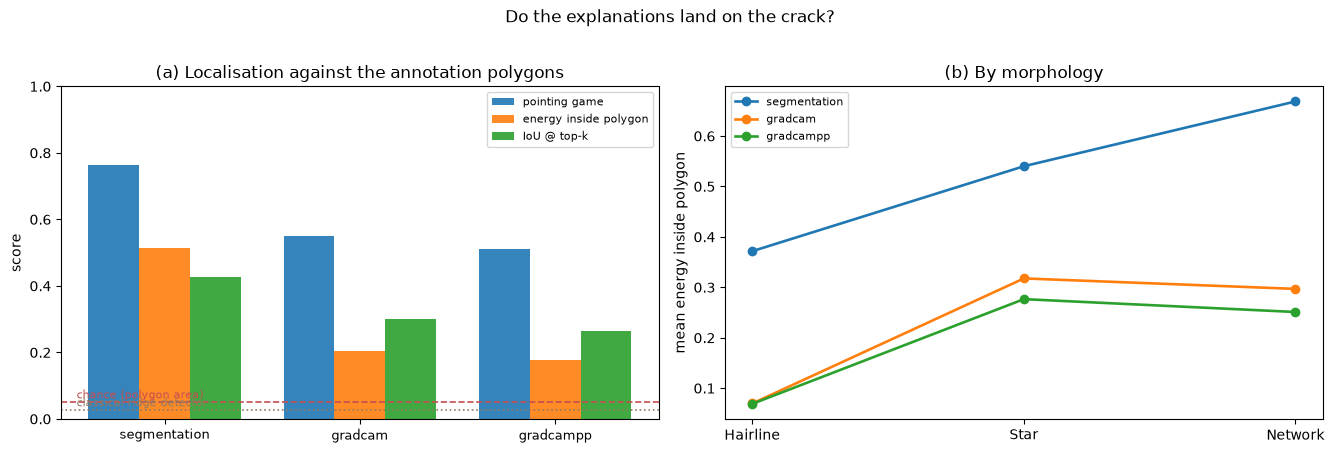

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))
ax = axes[0]
meth = list(summ.index); x = np.arange(len(meth)); w = 0.26
for i, (col, lab) in enumerate([("pointing_game", "pointing game"),
                                ("energy_inside", "energy inside polygon"),
                                ("iou_topk", "IoU @ top-k")]):
    ax.bar(x + (i - 1) * w, summ[col], w, label=lab, alpha=0.9)
ax.axhline(float(summ["chance_energy"].iloc[0]), ls="--", color="#C44E52", lw=1.2)
ax.text(-0.45, float(summ["chance_energy"].iloc[0]) + 0.01, "chance (polygon area)",
        fontsize=8, color="#C44E52")
ax.axhline(0.028, ls=":", color="#937860", lw=1.2)
ax.text(-0.45, 0.038, "classical ridge detector", fontsize=8, color="#937860")
ax.set_xticks(x); ax.set_xticklabels(meth, fontsize=9)
ax.set_ylabel("score"); ax.set_ylim(0, 1.0)
ax.set_title("(a) Localisation against the annotation polygons"); ax.legend(fontsize=8)

ax = axes[1]
for method in meth:
    sub = loc[loc["method"].eq(method)]
    v = [sub.loc[sub["pattern"].eq(p), "energy_inside"].mean() for p in CFG.PATTERNS]
    ax.plot(CFG.PATTERNS, v, "o-", lw=1.9, label=method)
ax.set_ylabel("mean energy inside polygon"); ax.set_title("(b) By morphology")
ax.legend(fontsize=8)
fig.suptitle("Do the explanations land on the crack?", y=1.02, fontsize=12)
fig.tight_layout(); fig.savefig(FIG_DIR / "01_localisation.png", bbox_inches="tight")
plt.show()

---
## 2. Gallery

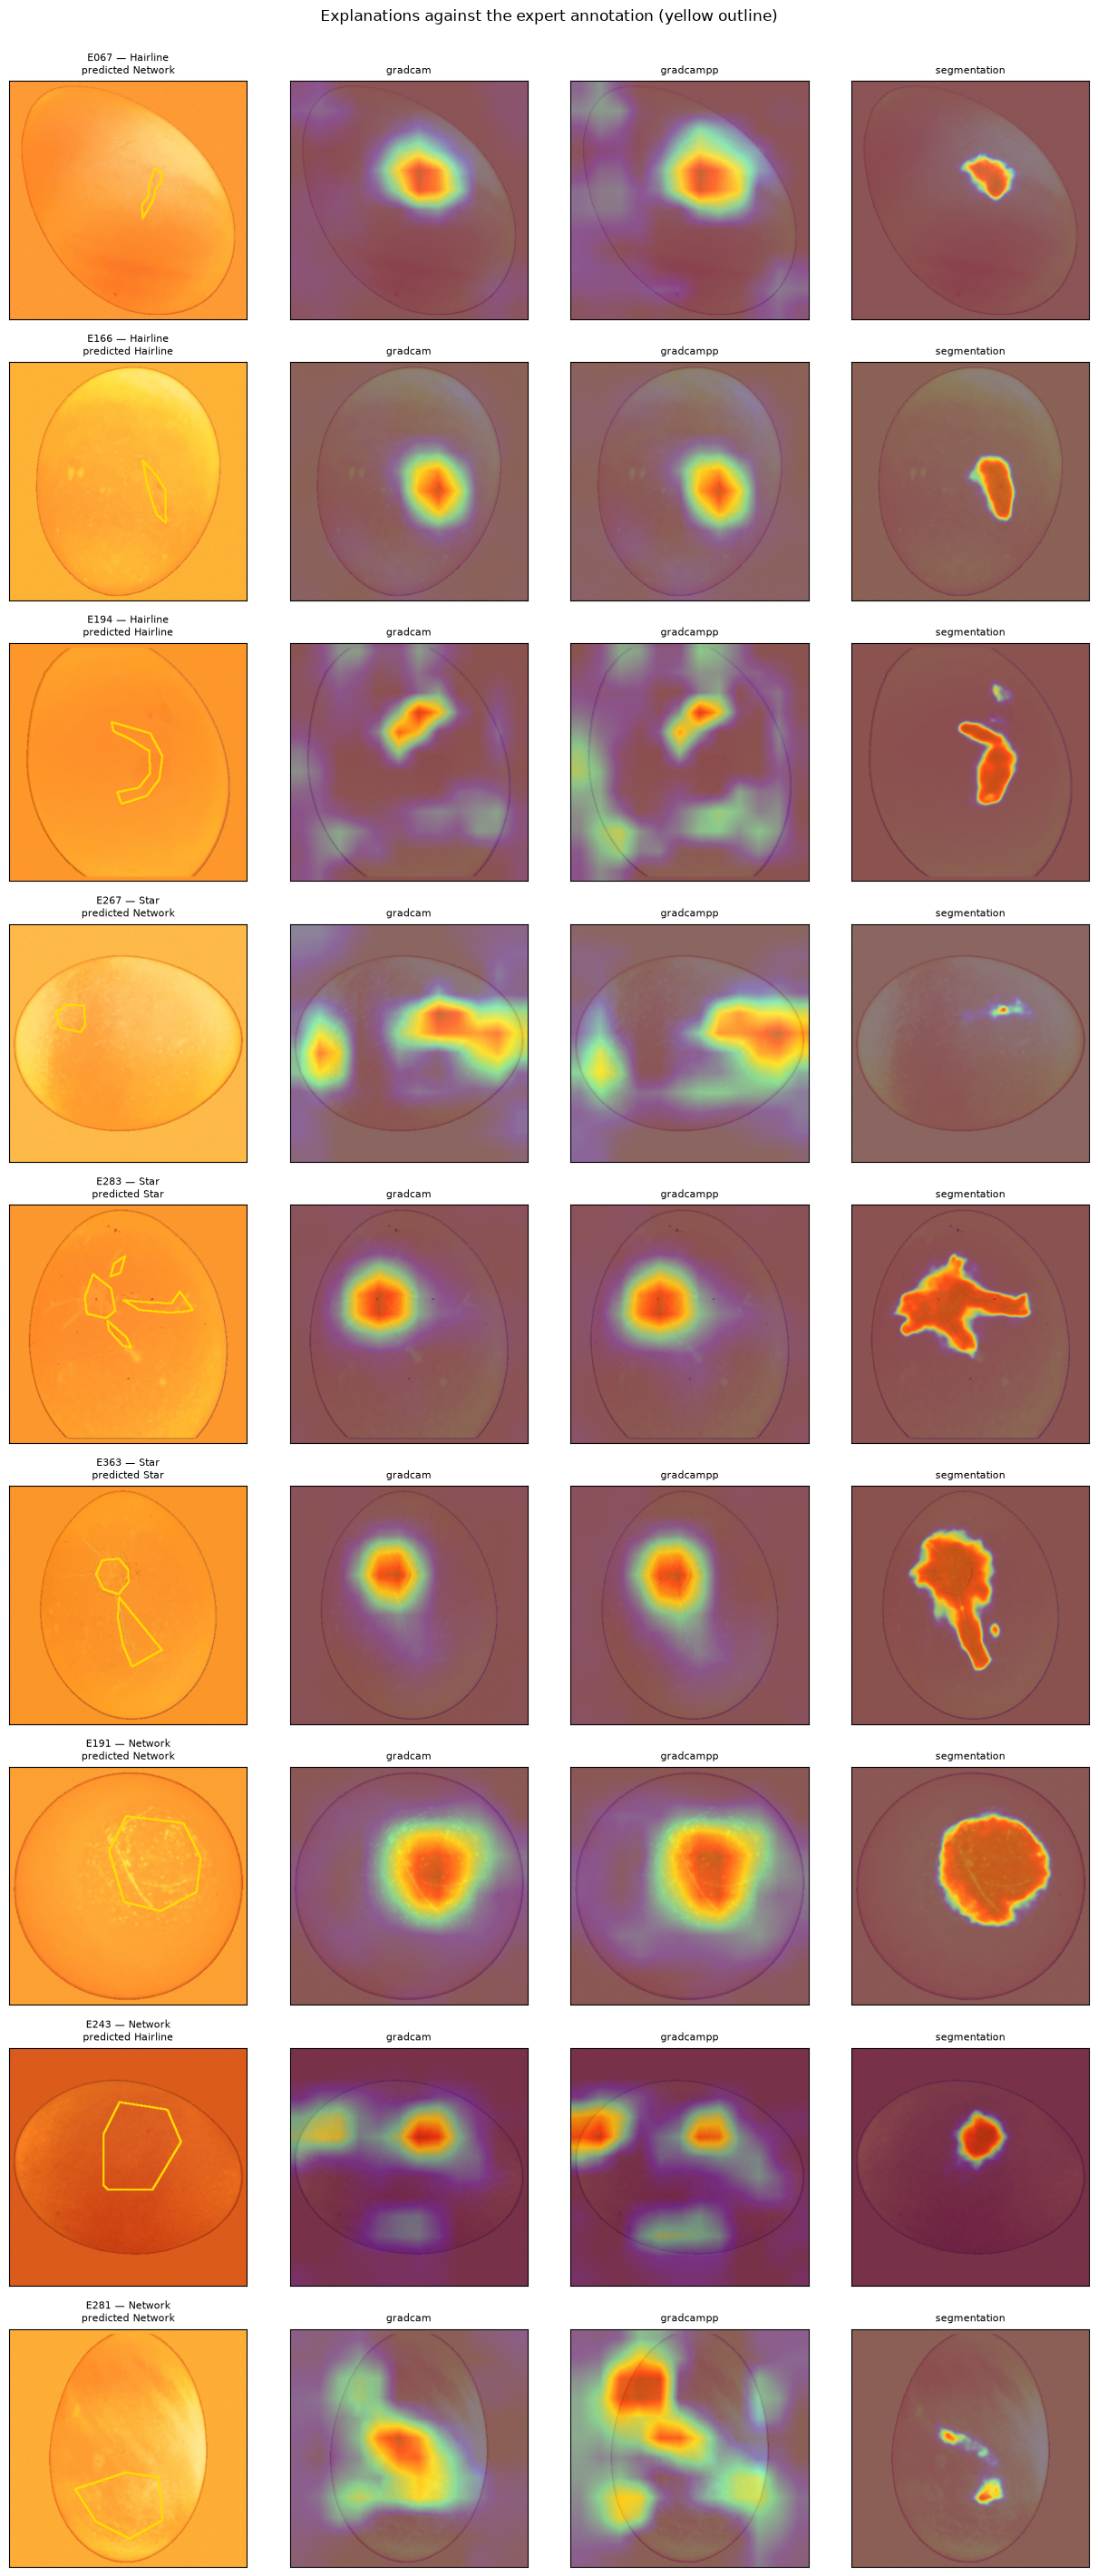

In [7]:
def overlay(img, heat, alpha=0.45):
    hm = cv2.applyColorMap((np.clip(heat, 0, 1) * 255).astype(np.uint8),
                           cv2.COLORMAP_JET)[:, :, ::-1]
    base = cv2.resize(img, (TRAIN_SIDE, TRAIN_SIDE), interpolation=cv2.INTER_AREA)
    return (base * (1 - alpha) + hm * alpha).astype(np.uint8)

sel = []
for p in CFG.PATTERNS:
    cand = [r for r in TEST_CRACKED if str(splits.loc[int(r), "crack_pattern"]) == p]
    sel += list(cand[:max(1, N_GALLERY // 3)])
sel = sel[:N_GALLERY]

fig, axes = plt.subplots(len(sel), 4, figsize=(12.6, 3.15 * len(sel)))
axes = np.atleast_2d(axes)
for i, r in enumerate(sel):
    img, _ = prep(int(r))
    heats, cls = cams_for(int(r))
    m = MASKS[int(r)]
    cont, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    base = cv2.resize(img, (TRAIN_SIDE, TRAIN_SIDE), interpolation=cv2.INTER_AREA).copy()
    cv2.drawContours(base, cont, -1, (255, 220, 0), 2)
    panels = [("image + annotation", base)] + [(k, overlay(img, v)) for k, v in heats.items()]
    for j, (lab, im) in enumerate(panels):
        axes[i, j].imshow(im)
        ttl = (f"{splits.loc[int(r), 'egg_id']} — {splits.loc[int(r), 'crack_pattern']}\n"
               f"predicted {CFG.LABEL4[cls]}") if j == 0 else lab
        axes[i, j].set_title(ttl, fontsize=8)
        axes[i, j].set_xticks([]); axes[i, j].set_yticks([]); axes[i, j].grid(False)
fig.suptitle("Explanations against the expert annotation (yellow outline)", y=1.0, fontsize=12)
fig.tight_layout(); fig.savefig(FIG_DIR / "02_gallery.png", bbox_inches="tight")
plt.show()

In [8]:
def _safe(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    return str(o)
(OUT / "explainability_summary.json").write_text(json.dumps(S, indent=2, default=_safe))

L = ["=" * 70, "NOTEBOOK 09 DIGEST -- EXPLAINABILITY", "=" * 70,
     f"generated: {S['generated_at']}",
     f"test eggs with a polygon: {S['n_test_cracked']}  "
     f"mean polygon area {S['mean_polygon_area_pct']}% of frame", "",
     "LOCALISATION (higher is better; chance = polygon area fraction)"]
for r in S["localisation"]:
    L.append(f"   {r['method']:<14s} pointing {r['pointing_game']:.3f}  "
             f"energy {r['energy_inside']:.3f} (x{r['energy_lift_over_chance']} chance)  "
             f"IoU {r['iou_topk']:.3f}")
L += ["", "BY MORPHOLOGY"]
for r in S.get("by_pattern", []):
    L.append(f"   {r['method']:<14s} {r['pattern']:<9s} n={r['n']:<3d} "
             f"pointing {r['pointing']:.3f}  energy {r['energy']:.3f}")
if "seg_vs_gradcam" in S:
    v = S["seg_vs_gradcam"]
    L += ["", f"SEGMENTATION HEAD vs GRAD-CAM: {v['mean_diff']:+.4f} ± {v['sd_diff']:.4f}, "
              f"better on {v['seg_better_pct']}% of eggs, p = {v['wilcoxon_p']}"]
L.append("=" * 70)
digest = "\n".join(L)
(OUT / "digest.txt").write_text(digest)
print(digest)

NOTEBOOK 09 DIGEST -- EXPLAINABILITY
generated: 2026-10-09T23:18:28
test eggs with a polygon: 51  mean polygon area 5.177% of frame

LOCALISATION (higher is better; chance = polygon area fraction)
   segmentation   pointing 0.765  energy 0.513 (x9.9 chance)  IoU 0.427
   gradcam        pointing 0.549  energy 0.203 (x3.93 chance)  IoU 0.300
   gradcampp      pointing 0.510  energy 0.178 (x3.44 chance)  IoU 0.263

BY MORPHOLOGY
   gradcam        Hairline  n=22  pointing 0.273  energy 0.070
   gradcam        Network   n=18  pointing 0.667  energy 0.297
   gradcam        Star      n=11  pointing 0.909  energy 0.318
   gradcampp      Hairline  n=22  pointing 0.227  energy 0.069
   gradcampp      Network   n=18  pointing 0.667  energy 0.251
   gradcampp      Star      n=11  pointing 0.818  energy 0.277
   segmentation   Hairline  n=22  pointing 0.682  energy 0.372
   segmentation   Network   n=18  pointing 0.833  energy 0.668
   segmentation   Star      n=11  pointing 0.818  energy 0.540

SE